# Feature C — Unsupervised Thumbnail Grouping

Goal: group all product thumbnails using visual information only. Site search/category labels are excluded from preprocessing, feature extraction, tuning, cluster-count selection, and final model selection. They are used only afterward as an external sense-check.


## 1. Colab setup


In [1]:
# Run once in Google Colab
!pip install -q torch torchvision scikit-learn pillow pandas matplotlib seaborn joblib

# If the project is in Google Drive, uncomment and edit:
# from google.colab import drive
# drive.mount('/content/drive')
# %cd '/content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence'


In [2]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT = Path('/content/drive/MyDrive/Amazon Mini Projects/Amazon-Marketplace-Product-Intelligence')
except ImportError:
    PROJECT = Path.cwd()
    if not (PROJECT / 'analysis').exists():
        PROJECT = PROJECT.parent

assert (PROJECT / 'analysis').exists(), f'Project folder is incorrect: {PROJECT}'
sys.path.insert(0, str(PROJECT))

from analysis.image_grouping import (
    add_stability_scores, audit_image_quality, build_image_index,
    compare_clusterings, describe_groups, extract_cnn_embeddings,
    extract_color_features, plot_group_samples, quality_outliers,
    reduce_features, save_grouping, select_best_clustering,
    validate_with_categories,
)

sns.set_theme(style='whitegrid')
OUTPUT_DIR = PROJECT / 'data' / 'models' / 'ThumbnailGrouping'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Project:', PROJECT)
print('Output:', OUTPUT_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project: /content/drive/MyDrive/Amazon Mini Projects/Amazon-Marketplace-Product-Intelligence
Output: /content/drive/MyDrive/Amazon Mini Projects/Amazon-Marketplace-Product-Intelligence/data/models/ThumbnailGrouping


## 2. Preprocessing audit

Actions and reasons:

| Action | Reason |
|---|---|
| Verify every image with Pillow | Reject corrupt/non-image files |
| Match filename stem to ASIN | Preserve a stable product-image identity |
| Convert to RGB | Give every image the same three-channel format |
| Resize and ImageNet-normalize for CNN | Match the pretrained model input |
| Sort by ASIN and use fixed seeds | Reproduce the same result |
| Exclude category/search fields | Meet the unsupervised grouping requirement |


In [3]:
index, failures = build_image_index()
index, exact_duplicates, near_duplicates = audit_image_quality(index, near_duplicate_distance=3)

print('Valid images:', len(index))
print('Corrupt images:', len(failures))
print('Unique ASINs:', index['asin'].nunique())
print('Exact duplicate-image rows:', len(exact_duplicates))
print('Near-duplicate candidate pairs:', len(near_duplicates))
print('Low-information/blank candidates:', int(index['low_information'].sum()))
display(index)
if len(failures): display(failures)
if len(exact_duplicates): display(exact_duplicates)
if len(near_duplicates): display(near_duplicates.head(50))

assert len(index) == index['asin'].nunique()
assert failures.empty

# Exact duplicates are reported rather than silently removed because different ASINs may
# legitimately reuse a product image. Inspect any reported rows before deciding to exclude them.


Valid images: 859
Corrupt images: 0
Unique ASINs: 859
Exact duplicate-image rows: 4
Near-duplicate candidate pairs: 250
Low-information/blank candidates: 4


,asin,image_path,filename,bytes,width,height,aspect_ratio,image_format,search_keyword,title,...,image_url,pixel_hash,brightness,contrast,white_background_ratio,dark_pixel_ratio,mean_red,mean_green,mean_blue,low_information
0,8883707168,/content/drive/MyDrive/Amazon Mini Projects/Am...,8883707168.jpg,421867,1475,2560,0.576172,JPEG,notebook journal,"""Moleskine Classic Notebook, Soft Cover, Large...",...,https://m.media-amazon.com/images/I/81wnidjYT4...,0687847dccc56d84a9fb9812de50ed524e6dd13450063a...,0.349552,0.361176,0.085693,0.038574,0.371618,0.354881,0.322159,False
1,B00004UE2D,/content/drive/MyDrive/Amazon Mini Projects/Am...,B00004UE2D.jpg,67811,900,1200,0.750000,JPEG,yamaha accoustic guitar,Yamaha C40 Full Size Nylon-String Classical Gu...,...,https://m.media-amazon.com/images/I/61zIszX+2Y...,e704eb977edd1fe3490f2772d0c472fd8bcacbea09cee4...,0.872686,0.258918,0.771973,0.000000,0.913105,0.879101,0.825856,False
2,B00006IDM7,/content/drive/MyDrive/Amazon Mini Projects/Am...,B00006IDM7.jpg,418555,2560,2560,1.000000,JPEG,notebook journal,"Mead Composition Notebook, Wide Ruled Paper, 7...",...,https://m.media-amazon.com/images/I/81ZeOTc7jZ...,3a42bc3e3f5d8ed4ad8ba8a96d5c1dd626cc103477c213...,0.473515,0.378949,0.302979,0.003174,0.468632,0.471417,0.480503,False
3,B00006IV0Q,/content/drive/MyDrive/Amazon Mini Projects/Am...,B00006IV0Q.jpg,112137,2000,2000,1.000000,JPEG,coffee maker,Presto 02811 Stainless Steel 12-Cup Electric C...,...,https://m.media-amazon.com/images/I/61rUS9j-40...,3ce174eb0249eb54fa45c15cd207fc87c837762700fcb1...,0.862052,0.240044,0.624268,0.001221,0.862402,0.862379,0.861371,False
4,B00009J580,/content/drive/MyDrive/Amazon Mini Projects/Am...,B00009J580.jpg,86801,900,1200,0.750000,JPEG,yamaha accoustic guitar,"Yamaha JR1 FG Junior 3/4 Size Acoustic Guitar,...",...,https://m.media-amazon.com/images/I/6106Lfreys...,b4bfb438b5b33be03882869ee1f4079648cbf813a32779...,0.873631,0.259371,0.762939,0.003418,0.916704,0.877287,0.826899,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
854,B0HCY3X5RF,/content/drive/MyDrive/Amazon Mini Projects/Am...,B0HCY3X5RF.jpg,139291,1600,1600,1.000000,JPEG,smartwatch,"Smart Watch for Men Women, 1.83"" HD Touch Scre...",...,https://m.media-amazon.com/images/I/714sV1Ls+4...,c5e9dfd2d477e8520b5758d6b586aba585734d95bc41da...,0.482461,0.382759,0.294189,0.136475,0.481442,0.481857,0.484092,False
855,B0HDBKMR2F,/content/drive/MyDrive/Amazon Mini Projects/Am...,B0HDBKMR2F.jpg,90066,1600,1600,1.000000,JPEG,coffee maker,"12 Cup Coffee Maker with LED Display, Drip Cof...",...,https://m.media-amazon.com/images/I/61DktIhBEy...,c1f34674c1160a7cc7338c0a3ab9d40ce5a9c5f53847f2...,0.700404,0.390129,0.583984,0.085693,0.703893,0.700013,0.697309,False
856,B0HDN4SV8F,/content/drive/MyDrive/Amazon Mini Projects/Am...,B0HDN4SV8F.jpg,124435,1500,1474,1.017639,JPEG,smartwatch,"Smart Watch for Men Women, 1.83"" HD Touchscree...",...,https://m.media-amazon.com/images/I/61v2c9Z0Me...,30a53d0b2bcd89d00294e42fb8e1b910d9f09ca5546907...,0.366608,0.363096,0.200684,0.194824,0.368180,0.368662,0.362989,False
857,B0HDSH3YR3,/content/drive/MyDrive/Amazon Mini Projects/Am...,B0HDSH3YR3.jpg,159758,2000,2000,1.000000,JPEG,wireless earbuds,Monster Clarity 200 Wireless Earbuds – Bluetoo...,...,https://m.media-amazon.com/images/I/71C1S1Nwwk...,862403bf5934c213c8cb1000ad1da2955567a8988b8425...,0.672004,0.389702,0.558105,0.049072,0.672329,0.672109,0.671586,False


,asin,filename,pixel_hash
0,B08PPZWNCV,B08PPZWNCV.jpg,2717a03db5916a631188a96044ba60625679e8259319ef...
1,B08PQ2KWHS,B08PQ2KWHS.jpg,2717a03db5916a631188a96044ba60625679e8259319ef...
2,B00FLYWNYQ,B00FLYWNYQ.jpg,481862831355e312202c485dbfb9fef58cff01071f260a...
3,B01B1VC13K,B01B1VC13K.jpg,481862831355e312202c485dbfb9fef58cff01071f260a...


,asin_left,asin_right,difference_hash_distance
0,B00004UE2D,B00009J580,3
1,B00004UE2D,B00EIB33B0,1
2,B00004UE2D,B01CFOB3LS,1
3,B00004UE2D,B078WYJ3HR,2
4,B00004UE2D,B0BYFC65L7,3
5,B00009J580,B005F25DUU,3
6,B00009J580,B01N9SO8WT,2
7,B00009J580,B078WXWNBT,3
8,B00009J580,B07965TCK1,3
9,B00009J580,B0BYFC65L7,2


### 2.1 Preview images immediately after loading

This random, reproducible sample confirms that the image paths were read correctly before feature extraction or clustering. Only image pixels and ASIN filenames are shown; category labels are not used.


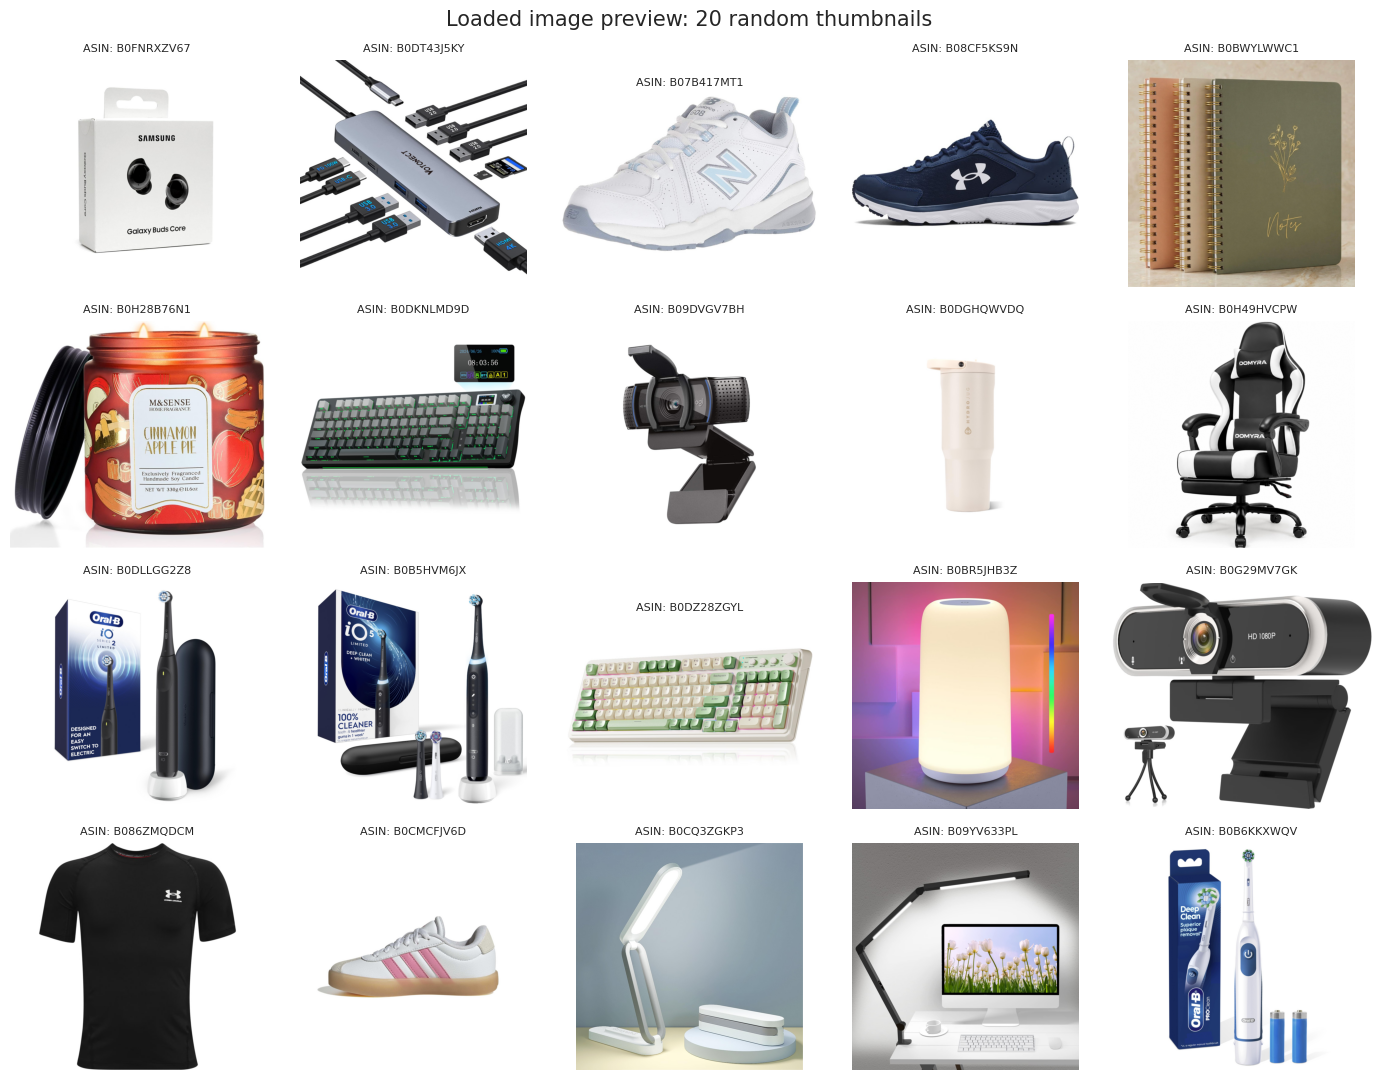

In [4]:
n_preview = min(20, len(index))
preview = index.sample(n_preview, random_state=42)
rows, cols = 4, 5
fig, axes = plt.subplots(rows, cols, figsize=(14, 11))
axes = np.asarray(axes).ravel()

for axis, (_, row) in zip(axes, preview.iterrows()):
    with Image.open(row['image_path']) as image:
        axis.imshow(image.convert('RGB'))
    axis.set_title(f"ASIN: {row['asin']}", fontsize=8)
    axis.axis('off')

for axis in axes[n_preview:]:
    axis.axis('off')

plt.suptitle(f'Loaded image preview: {n_preview} random thumbnails', fontsize=15)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'loaded_image_preview.png', dpi=160, bbox_inches='tight')
plt.show()


## 3. Image EDA without category labels


,bytes,width,height,aspect_ratio
count,859.000000,859.000000,859.000000,859.000000
mean,161478.821886,1798.630966,1862.563446,0.978906
std,95518.128559,459.955509,452.152847,0.180976
min,14105.000000,512.000000,512.000000,0.332000
25%,95159.000000,1534.000000,1600.000000,1.000000
50%,144420.000000,1680.000000,2000.000000,1.000000
75%,200935.000000,2000.000000,2048.000000,1.000000
max,769218.000000,2560.000000,2560.000000,2.655602


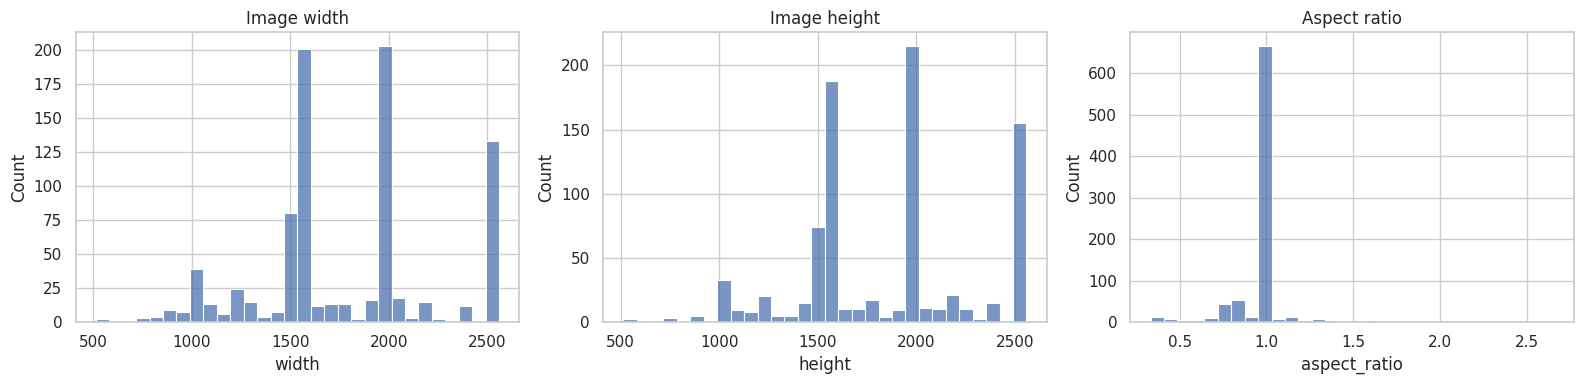

In [5]:
display(index[['bytes','width','height','aspect_ratio']].describe())

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(index['width'], bins=30, ax=axes[0])
axes[0].set_title('Image width')
sns.histplot(index['height'], bins=30, ax=axes[1])
axes[1].set_title('Image height')
sns.histplot(index['aspect_ratio'], bins=30, ax=axes[2])
axes[2].set_title('Aspect ratio')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'image_eda_dimensions.png', dpi=160, bbox_inches='tight')
plt.show()


### 3.1 Pixel-level visual EDA

Technique: descriptive image statistics. Mean RGB values describe dominant colour; brightness describes light versus dark thumbnails; white-background ratio identifies catalogue-style product photography. These are computed from pixels only.


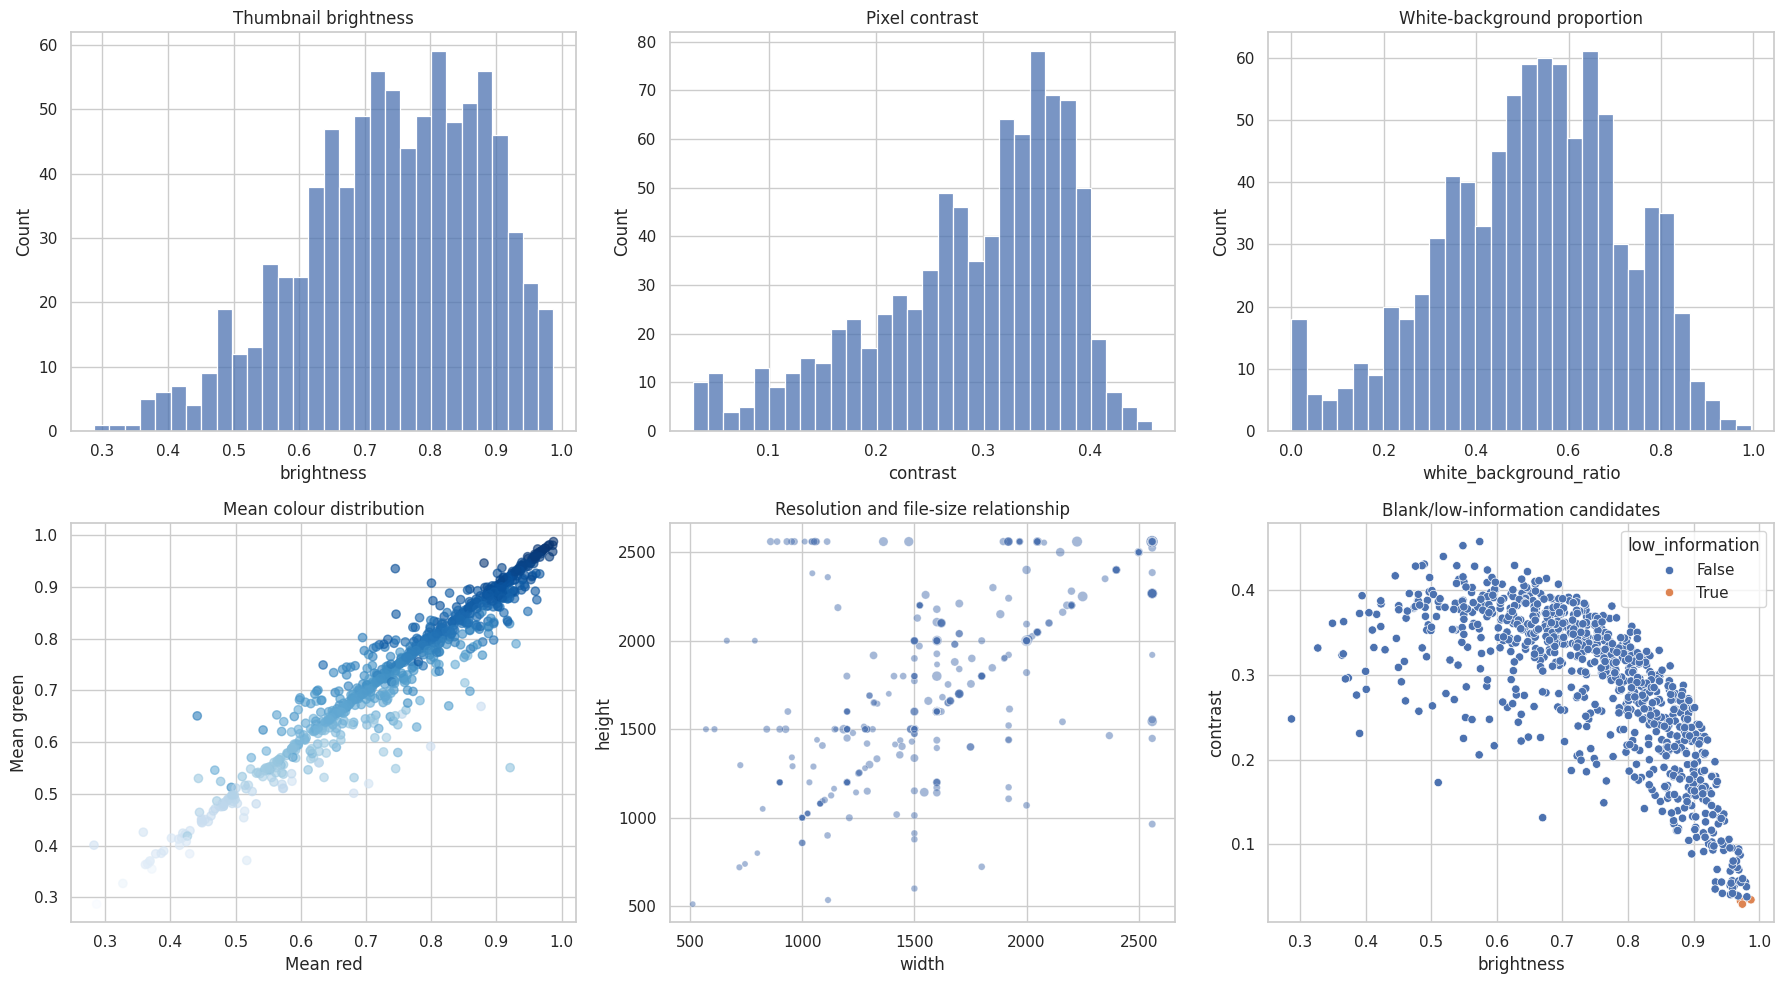

,mean_red,mean_green,mean_blue,brightness,contrast,white_background_ratio,dark_pixel_ratio
count,859.000000,859.000000,859.000000,859.000000,859.000000,859.000000,859.000000
mean,0.748750,0.739881,0.736819,0.741816,0.287861,0.520905,0.021086
std,0.142263,0.140114,0.141225,0.138665,0.091665,0.199746,0.039482
min,0.282893,0.287041,0.287034,0.287027,0.029305,0.000000,0.000000
25%,0.655238,0.649121,0.649014,0.652129,0.234305,0.384644,0.000000
50%,0.760247,0.752996,0.752597,0.753373,0.313249,0.538330,0.004150
75%,0.863936,0.851412,0.848709,0.852195,0.359108,0.661011,0.022705
max,0.987473,0.987427,0.992758,0.987507,0.457698,0.994873,0.289062


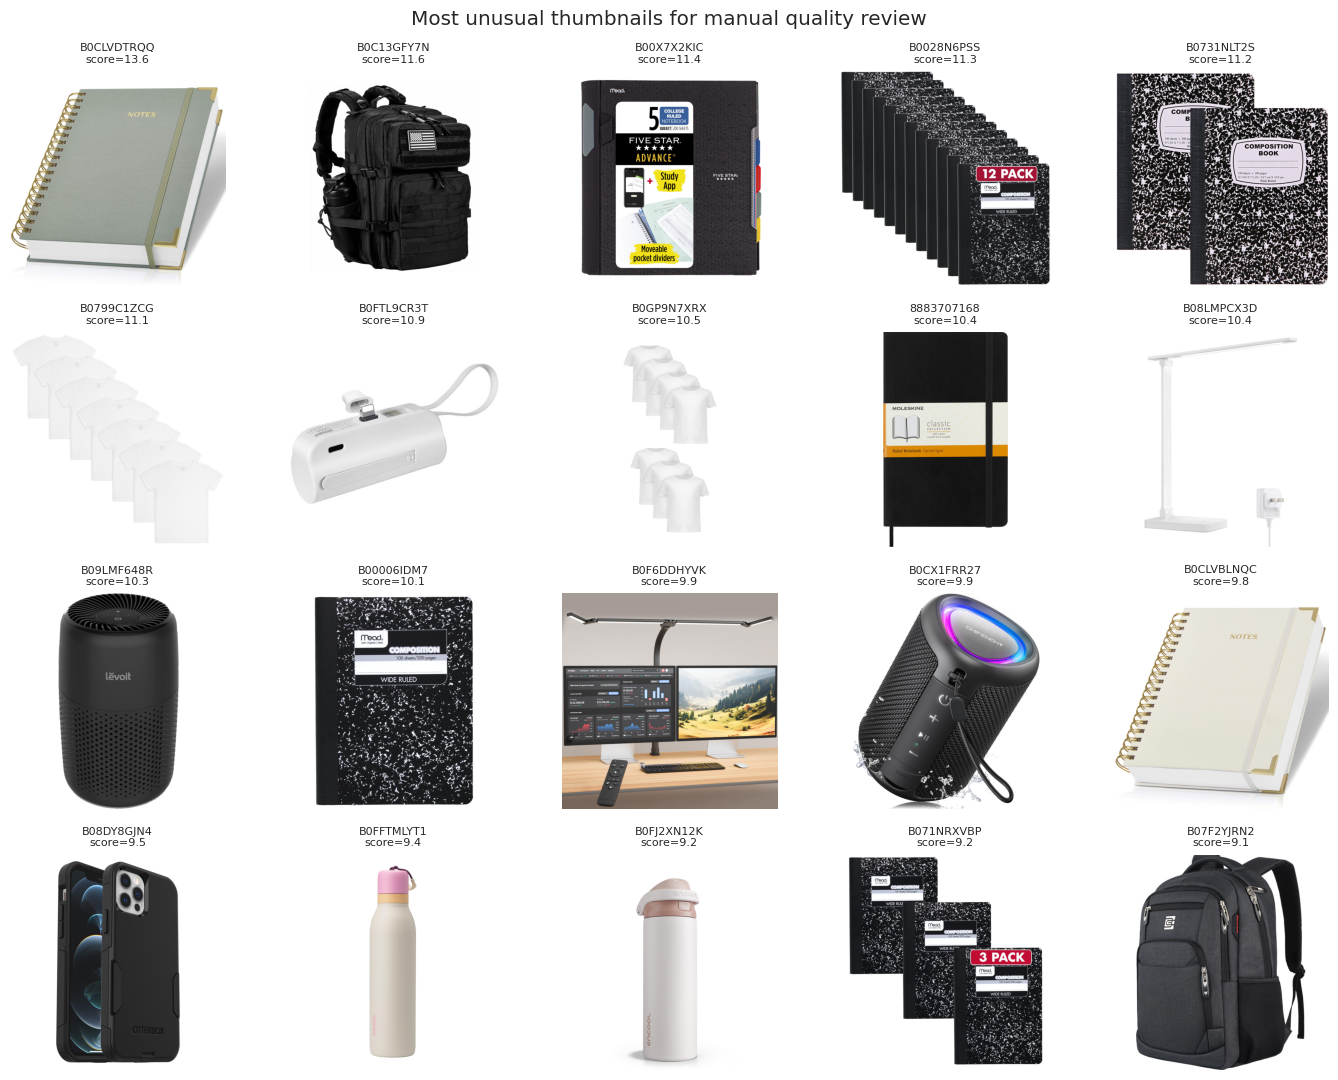

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
sns.histplot(index['brightness'], bins=30, ax=axes[0,0]); axes[0,0].set_title('Thumbnail brightness')
sns.histplot(index['contrast'], bins=30, ax=axes[0,1]); axes[0,1].set_title('Pixel contrast')
sns.histplot(index['white_background_ratio'], bins=30, ax=axes[0,2]); axes[0,2].set_title('White-background proportion')
axes[1,0].scatter(index['mean_red'], index['mean_green'], c=index['mean_blue'], cmap='Blues', alpha=.6)
axes[1,0].set_title('Mean colour distribution'); axes[1,0].set_xlabel('Mean red'); axes[1,0].set_ylabel('Mean green')
sns.scatterplot(data=index, x='width', y='height', size='bytes', alpha=.5, ax=axes[1,1], legend=False)
axes[1,1].set_title('Resolution and file-size relationship')
sns.scatterplot(data=index, x='brightness', y='contrast', hue='low_information', ax=axes[1,2])
axes[1,2].set_title('Blank/low-information candidates')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'pixel_level_eda.png', dpi=160, bbox_inches='tight')
plt.show()

display(index[['mean_red','mean_green','mean_blue','brightness','contrast','white_background_ratio','dark_pixel_ratio']].describe())

# Show the most unusual images instead of relying only on numeric outlier scores.
outliers = quality_outliers(index, limit=20)
fig, axes = plt.subplots(4, 5, figsize=(14, 11))
for axis, (_, row) in zip(axes.flat, outliers.iterrows()):
    with Image.open(row['image_path']) as image:
        axis.imshow(image.convert('RGB'))
    axis.set_title(f"{row['asin']}\nscore={row['quality_outlier_score']:.1f}", fontsize=8)
    axis.axis('off')
plt.suptitle('Most unusual thumbnails for manual quality review')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'quality_outlier_montage.png', dpi=160, bbox_inches='tight')
plt.show()


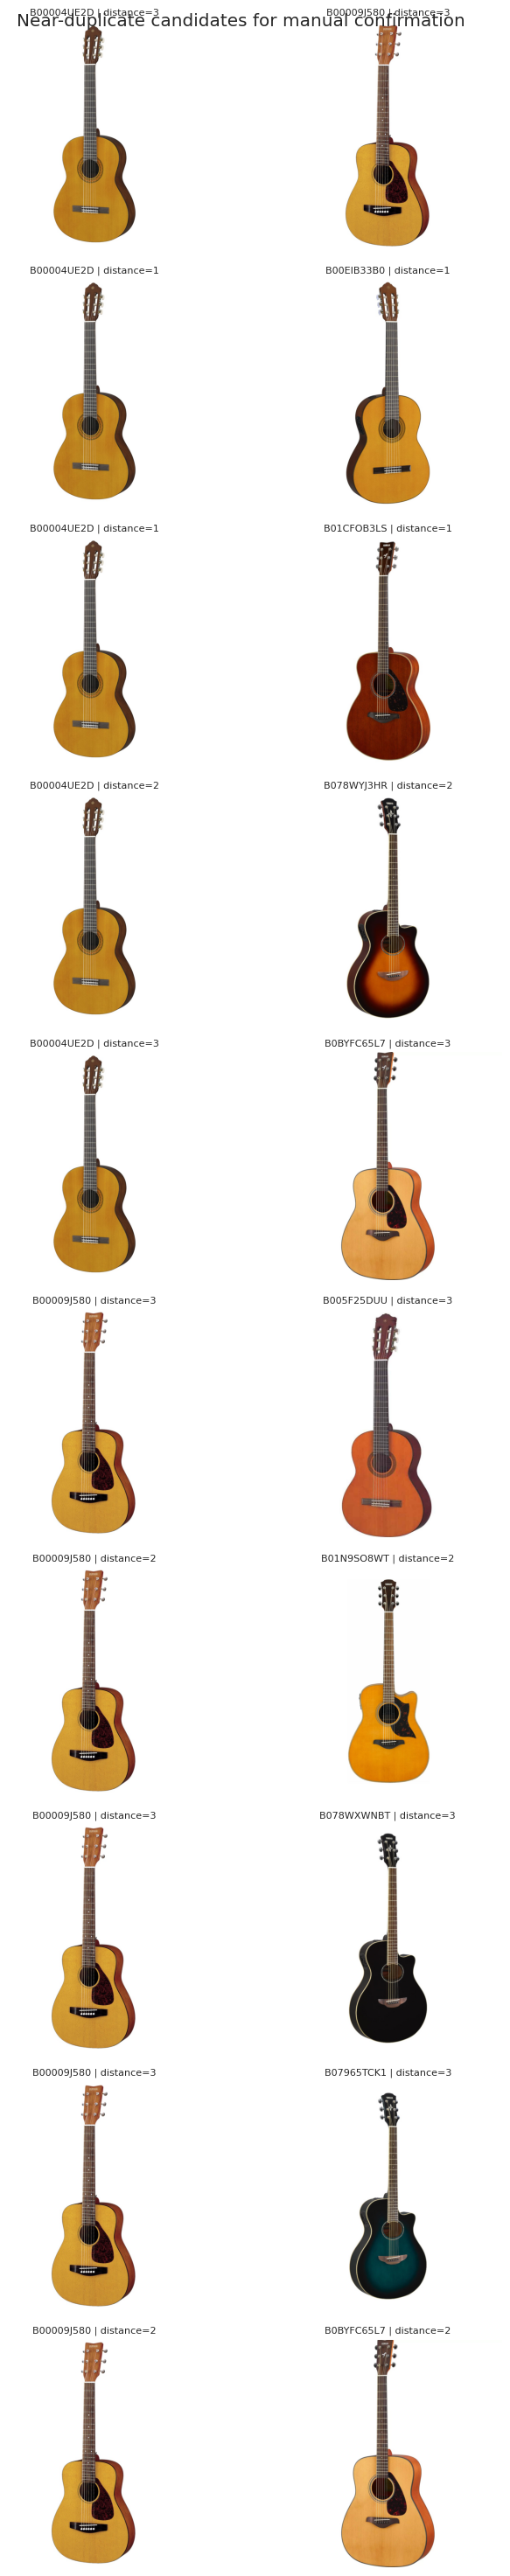

In [7]:
# Perceptual hashes create review candidates, not automatic deletions.
if len(near_duplicates):
    pairs = near_duplicates.head(10)
    path_lookup = index.set_index('asin')['image_path'].to_dict()
    fig, axes = plt.subplots(len(pairs), 2, figsize=(8, 3 * len(pairs)), squeeze=False)
    for row_number, pair in enumerate(pairs.itertuples(index=False)):
        for column, asin in enumerate([pair.asin_left, pair.asin_right]):
            with Image.open(path_lookup[asin]) as image:
                axes[row_number, column].imshow(image.convert('RGB'))
            axes[row_number, column].set_title(f'{asin} | distance={pair.difference_hash_distance}', fontsize=8)
            axes[row_number, column].axis('off')
    plt.suptitle('Near-duplicate candidates for manual confirmation')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'near_duplicate_review.png', dpi=160, bbox_inches='tight')
    plt.show()
else:
    print('No near-duplicate candidates at the selected distance threshold.')


Interpretation: dimensions and backgrounds vary, so raw pixels are unsuitable. Exact duplicates are reported explicitly; perceptual near-duplicates are reviewed side by side because similar catalogue photography can create false positives. Low-information and extreme images are shown rather than silently removed. A color-histogram baseline tests simple appearance, while pretrained CNN embeddings capture shape and visual semantics.


## 4. Extract two independent visual representations


In [8]:
color_cache = OUTPUT_DIR / 'color_features.npy'
cnn_cache = OUTPUT_DIR / 'resnet18_embeddings.npy'

if color_cache.exists():
    color_features = np.load(color_cache)
else:
    color_features = extract_color_features(index)
    np.save(color_cache, color_features)

if cnn_cache.exists():
    cnn_embeddings = np.load(cnn_cache)
    cnn_info = {'backbone':'resnet18', 'source':'cache'}
else:
    cnn_embeddings, cnn_info = extract_cnn_embeddings(
        index, backbone='resnet18', batch_size=32
    )
    np.save(cnn_cache, cnn_embeddings)

color_reduced, color_pca, color_components = reduce_features(
    color_features, max_components=64, variance=0.95
)
cnn_reduced, cnn_pca, cnn_components = reduce_features(
    cnn_embeddings, max_components=128, variance=0.95
)

print('Color representation:', color_features.shape, 'PCA components:', color_components)
print('CNN representation  :', cnn_embeddings.shape, 'PCA components:', cnn_components)
print(cnn_info)


Color representation: (859, 96) PCA components: 34
CNN representation  : (859, 512) PCA components: 128
{'backbone': 'resnet18', 'source': 'cache'}


No category, keyword, title, brand, or price value appears in either representation. PCA removes noise and reduces clustering cost; it is also fitted without labels.


### 4.1 Visualize feature spaces before clustering

Technique: two-dimensional PCA projection. This reduces each representation to two plotting dimensions so we can inspect spread, overlap, and possible natural structure. No cluster or category label is used in these plots.


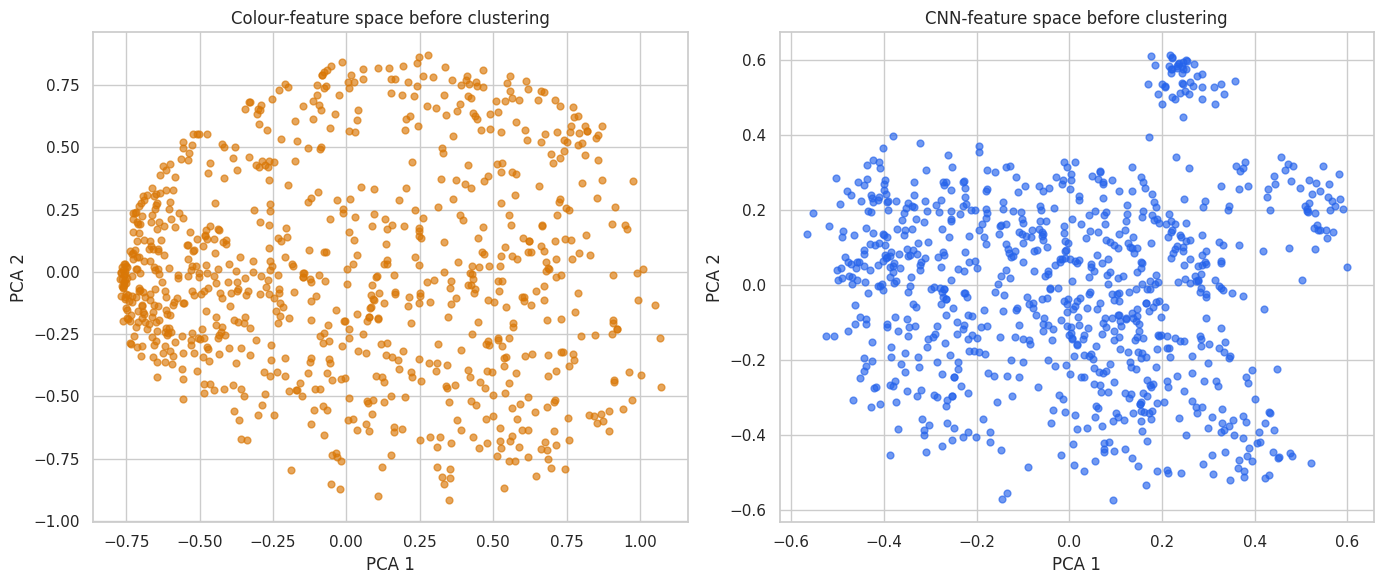

In [9]:
from sklearn.decomposition import PCA as PlotPCA

color_plot = PlotPCA(n_components=2, random_state=42).fit_transform(color_reduced)
cnn_plot = PlotPCA(n_components=2, random_state=42).fit_transform(cnn_reduced)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].scatter(color_plot[:,0], color_plot[:,1], s=24, alpha=.65, color='#D97706')
axes[0].set_title('Colour-feature space before clustering')
axes[0].set_xlabel('PCA 1'); axes[0].set_ylabel('PCA 2')
axes[1].scatter(cnn_plot[:,0], cnn_plot[:,1], s=24, alpha=.65, color='#2563EB')
axes[1].set_title('CNN-feature space before clustering')
axes[1].set_xlabel('PCA 1'); axes[1].set_ylabel('PCA 2')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'feature_space_before_clustering.png', dpi=160, bbox_inches='tight')
plt.show()


## 5. Model development, comparison, and cluster-count tuning


,approach,k,stability_mean_ari,stability_min_ari,silhouette,calinski_harabasz,davies_bouldin,smallest_group,largest_group_share
12,color_kmeans,4,0.983992,0.978179,0.213164,172.955048,1.904407,162,0.400466
0,color_kmeans,2,NaN,NaN,0.211582,233.542679,1.880855,400,0.534342
18,color_kmeans,5,0.983040,0.966533,0.210738,150.665466,1.798334,99,0.370198
6,color_kmeans,3,0.987929,0.974818,0.207840,198.464264,1.811595,198,0.431898
157,cnn_kmeans,28,0.756923,0.729875,0.186083,27.806990,2.133177,10,0.060536
...,...,...,...,...,...,...,...,...,...
28,cnn_agglomerative_complete,6,NaN,NaN,0.056801,31.373743,3.330508,45,0.261932
5,cnn_agglomerative_average,2,NaN,NaN,0.056332,50.475769,3.956310,318,0.629802
16,cnn_agglomerative_complete,4,NaN,NaN,0.045620,33.055374,3.815216,107,0.437718
10,cnn_agglomerative_complete,3,NaN,NaN,0.040921,32.526451,4.588990,225,0.437718


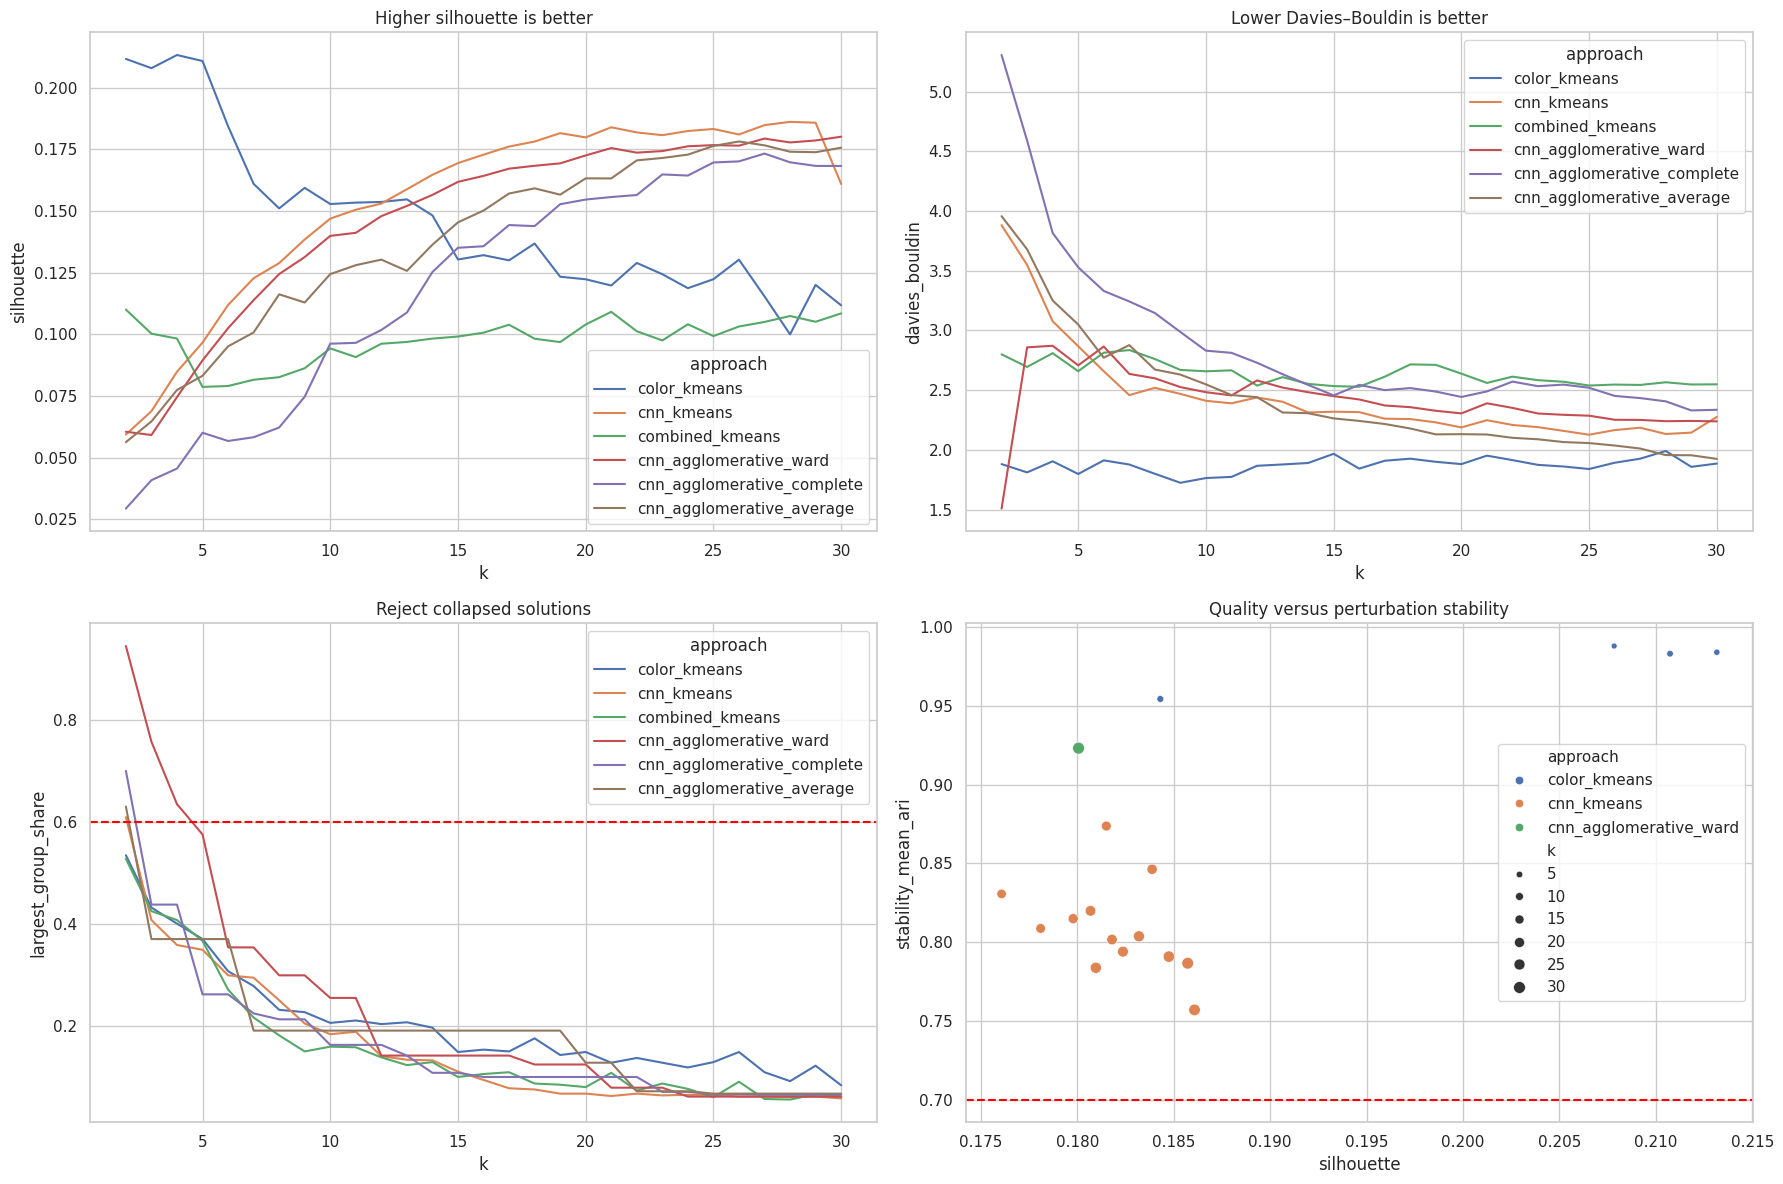

In [10]:
K_VALUES = range(2, 31)
results, fitted = compare_clusterings(
    color_reduced, cnn_reduced, k_values=K_VALUES,
    linkages=('ward', 'complete', 'average'),
)

# Stability is expensive, so test the 18 strongest size-eligible candidates.
results = add_stability_scores(
    results, fitted, top_n=18, runs=5, noise_scale=0.01
)
display(results.sort_values(['silhouette','stability_mean_ari'], ascending=[False,False]))

fig, axes = plt.subplots(2, 2, figsize=(18, 12))
sns.lineplot(data=results, x='k', y='silhouette', hue='approach', ax=axes[0,0])
axes[0,0].set_title('Higher silhouette is better')
sns.lineplot(data=results, x='k', y='davies_bouldin', hue='approach', ax=axes[0,1])
axes[0,1].set_title('Lower Davies–Bouldin is better')
sns.lineplot(data=results, x='k', y='largest_group_share', hue='approach', ax=axes[1,0])
axes[1,0].axhline(0.60, color='red', linestyle='--'); axes[1,0].set_title('Reject collapsed solutions')
stable_results = results.dropna(subset=['stability_mean_ari'])
sns.scatterplot(data=stable_results, x='silhouette', y='stability_mean_ari', hue='approach', size='k', ax=axes[1,1])
axes[1,1].axhline(0.70, color='red', linestyle='--'); axes[1,1].set_title('Quality versus perturbation stability')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'clustering_metric_comparison.png', dpi=160, bbox_inches='tight')
plt.show()


Compared approaches:

1. Color histograms + K-means: simple appearance baseline.
2. CNN embeddings + K-means: semantic visual features with compact groups.
3. Combined color+CNN features + K-means: appearance and semantic information together.
4. CNN agglomerative Ward linkage: variance-minimizing hierarchy.
5. CNN agglomerative complete linkage: compact clusters controlled by farthest pairs.
6. CNN agglomerative average linkage: groups controlled by average pair distance.

Cluster counts 2–30 are evaluated using silhouette, Calinski–Harabasz, Davies–Bouldin, and group balance. The strongest eligible candidates are rerun after small feature perturbations; mean ARI measures whether their assignments remain stable. Category labels are absent from every one of these decisions.


## 6. Final selection and explanation


In [11]:
winner, final = select_best_clustering(
    results, fitted, min_group_size=5, max_group_share=0.40, min_stability=0.50, min_k=12
)
labels = final['labels']
final_features = final['features']
group_sizes = pd.Series(labels).value_counts().sort_index().rename('group_size')

display(winner.to_frame('selected_value'))
display(group_sizes.to_frame())

print(
    f"We made {int(winner['k'])} visual groups using {winner['approach']}. "
    f"It passed the size constraints, achieved silhouette={winner['silhouette']:.3f}, "
    f"Davies–Bouldin={winner['davies_bouldin']:.3f}, and perturbation stability "
    f"ARI={winner['stability_mean_ari']:.3f}. Its smallest group has "
    f"{int(winner['smallest_group'])} images and the largest contains "
    f"{winner['largest_group_share']:.1%} of images."
)


,selected_value
approach,cnn_kmeans
k,28
stability_mean_ari,0.756923
stability_min_ari,0.729875
silhouette,0.186083
calinski_harabasz,27.80699
davies_bouldin,2.133177
smallest_group,10
largest_group_share,0.060536


,group_size
0,23
1,38
2,42
3,48
4,52
5,50
6,45
7,28
8,33
9,37


We made 28 visual groups using cnn_kmeans. It passed the size constraints, achieved silhouette=0.186, Davies–Bouldin=2.133, and perturbation stability ARI=0.757. Its smallest group has 10 images and the largest contains 6.1% of images.


### 6.1 Visualize the selected grouping

Techniques: a group-size bar chart checks balance, while a PCA scatter plot shows separation in the selected feature space. Colours here represent the final unsupervised groups, not Amazon categories.


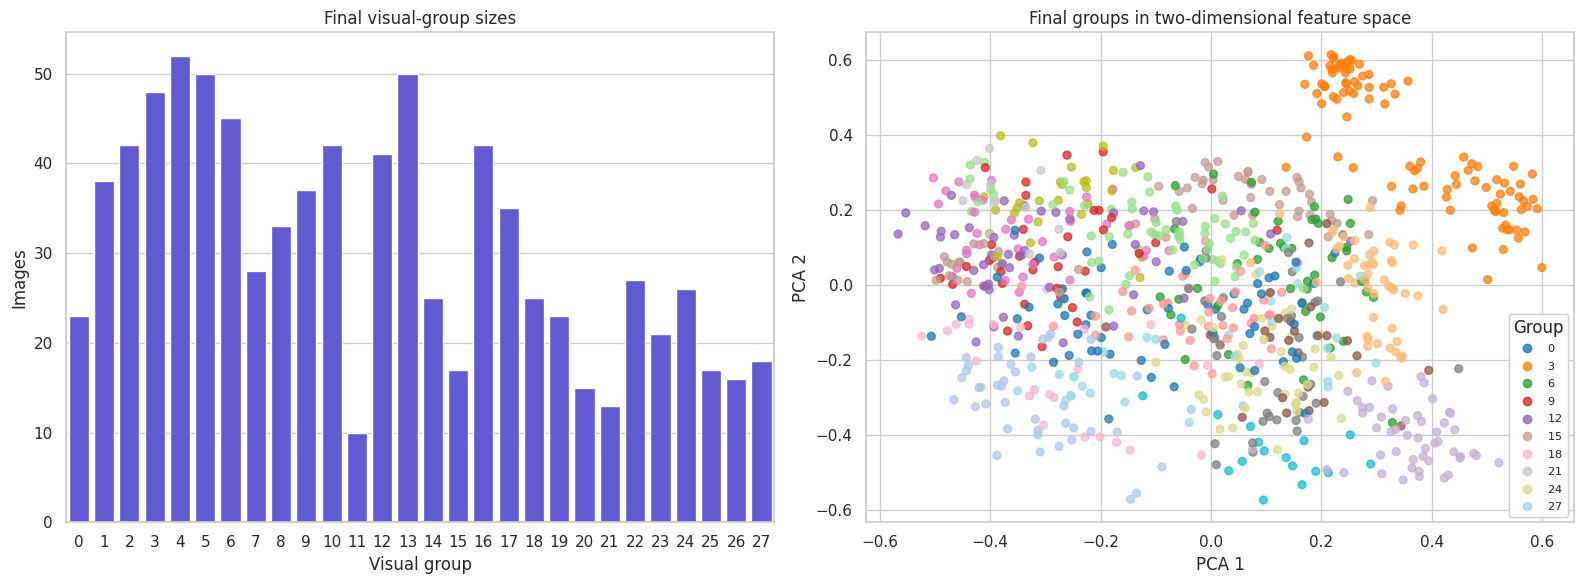

In [12]:
from sklearn.decomposition import PCA as PlotPCA

group_size_frame = group_sizes.rename_axis('visual_group').reset_index()
final_plot = PlotPCA(n_components=2, random_state=42).fit_transform(final_features)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(data=group_size_frame, x='visual_group', y='group_size', color='#4F46E5', ax=axes[0])
axes[0].set_title('Final visual-group sizes')
axes[0].set_xlabel('Visual group'); axes[0].set_ylabel('Images')

scatter = axes[1].scatter(
    final_plot[:,0], final_plot[:,1],
    c=labels, cmap='tab20', s=32, alpha=.75
)
axes[1].set_title('Final groups in two-dimensional feature space')
axes[1].set_xlabel('PCA 1'); axes[1].set_ylabel('PCA 2')
legend = axes[1].legend(*scatter.legend_elements(), title='Group', loc='best', fontsize=8)
axes[1].add_artist(legend)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'final_group_sizes_and_projection.png', dpi=160, bbox_inches='tight')
plt.show()


## 7. Representative images and group sizes


In [13]:
figure_path = OUTPUT_DIR / 'thumbnail_group_samples.png'
plot_group_samples(
    index, final_features, labels,
    samples_per_group=6,
    output_path=figure_path,
)
plt.show()

group_interpretation = describe_groups(index, labels)
display(group_interpretation)
group_interpretation.to_csv(OUTPUT_DIR / 'visual_group_descriptions.csv', index=False)
print('Saved figure:', figure_path)
print('Saved descriptions:', OUTPUT_DIR / 'visual_group_descriptions.csv')


Output hidden; open in https://colab.research.google.com to view.

The table supplies reproducible pixel-based descriptions—brightness, background, shape, and colour—while the centroid-nearest montage supplies qualitative evidence. In the final report, refine each description after inspecting its row of representative images. Describe visual appearance only; do not name a group from Amazon category labels.


## 8. Category-label validation after final selection


Adjusted Rand Index: 0.7664
Normalized Mutual Information: 0.8639
Cluster purity: 0.8626


search_keyword,DSLR camera,USB-C hub,air purifier,backpack,bluetooth speaker,budget laptop,candle,coffee maker,desk lamp LED,electric toothbrush,...,phone stand,portable charger,smartwatch,sneakers,sunglasses,t-shirt,water bottle,webcam HD,wireless earbuds,yamaha accoustic guitar
visual_group,,,,,,,,,,,,,,,,,,,,,
0,0,0,0,0,0,2,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1,0,4,0,2,0,0,1,3,1,...,5,6,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,42,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,48
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,52,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,50,0,0,0,0,0
6,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7,0,0,1,0,0,0,2,0,1,0,...,0,1,0,0,0,0,0,0,1,0
8,0,0,0,0,0,12,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


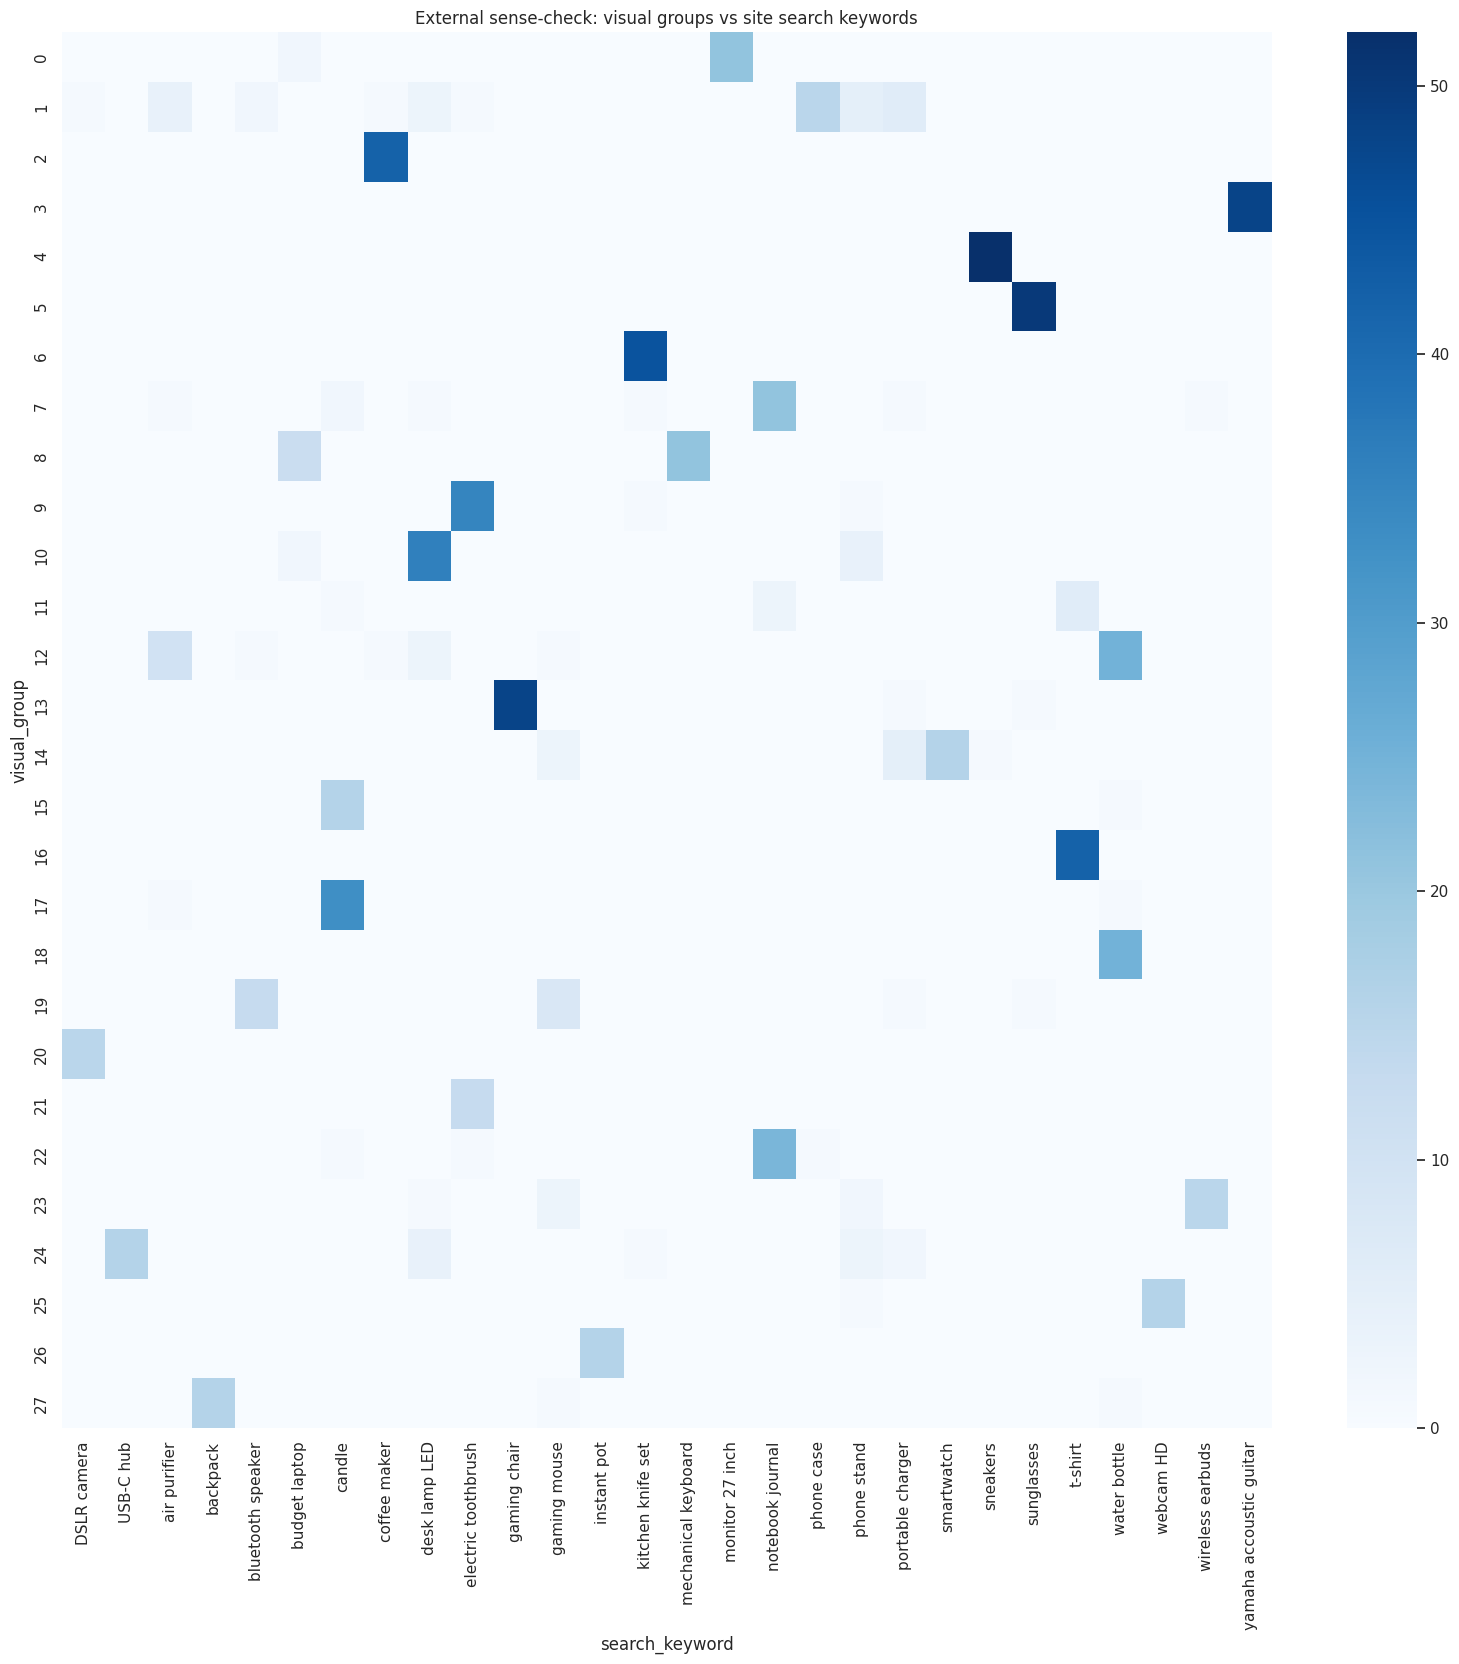

In [14]:
validation = validate_with_categories(index, labels)
print('Adjusted Rand Index:', round(validation['adjusted_rand_index'], 4))
print('Normalized Mutual Information:', round(validation['normalized_mutual_info'], 4))
print('Cluster purity:', round(validation['cluster_purity'], 4))

category_table = validation['cross_tab']
display(category_table)
plt.figure(figsize=(16, max(5, int(winner['k']) * 0.6)))
sns.heatmap(category_table, cmap='Blues')
plt.title('External sense-check: visual groups vs site search keywords')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'category_validation_heatmap.png', dpi=160, bbox_inches='tight')
plt.show()


These category metrics are diagnostic only and cannot change the selected model or cluster count. Interpret them explicitly: ARI/NMI near zero means the groups capture photographic style, background, colour, or shape rather than marketplace product semantics; higher values mean visual appearance also aligns with categories. Low agreement is not hidden or called high performance—it defines what the discovered groups actually represent.


## 9. Save final assignments and model artifacts


In [15]:
assignments = save_grouping(
    index=index,
    labels=labels,
    features=final_features,
    winner=winner,
    model=final['model'],
    output_dir=OUTPUT_DIR,
)
display(assignments[['asin','filename','visual_group','title']])
print('Saved assignments:', OUTPUT_DIR / 'thumbnail_groups.csv')
print('Saved features:', OUTPUT_DIR / 'thumbnail_features.npz')
print('Saved model:', OUTPUT_DIR / 'clustering_model.joblib')


,asin,filename,visual_group,title
0,8883707168,8883707168.jpg,22,"""Moleskine Classic Notebook, Soft Cover, Large..."
1,B00004UE2D,B00004UE2D.jpg,3,Yamaha C40 Full Size Nylon-String Classical Gu...
2,B00006IDM7,B00006IDM7.jpg,22,"Mead Composition Notebook, Wide Ruled Paper, 7..."
3,B00006IV0Q,B00006IV0Q.jpg,2,Presto 02811 Stainless Steel 12-Cup Electric C...
4,B00009J580,B00009J580.jpg,3,"Yamaha JR1 FG Junior 3/4 Size Acoustic Guitar,..."
...,...,...,...,...
854,B0HCY3X5RF,B0HCY3X5RF.jpg,14,"Smart Watch for Men Women, 1.83"" HD Touch Scre..."
855,B0HDBKMR2F,B0HDBKMR2F.jpg,2,"12 Cup Coffee Maker with LED Display, Drip Cof..."
856,B0HDN4SV8F,B0HDN4SV8F.jpg,14,"Smart Watch for Men Women, 1.83"" HD Touchscree..."
857,B0HDSH3YR3,B0HDSH3YR3.jpg,23,Monster Clarity 200 Wireless Earbuds – Bluetoo...


Saved assignments: /content/drive/MyDrive/Amazon Mini Projects/Amazon-Marketplace-Product-Intelligence/data/models/ThumbnailGrouping/thumbnail_groups.csv
Saved features: /content/drive/MyDrive/Amazon Mini Projects/Amazon-Marketplace-Product-Intelligence/data/models/ThumbnailGrouping/thumbnail_features.npz
Saved model: /content/drive/MyDrive/Amazon Mini Projects/Amazon-Marketplace-Product-Intelligence/data/models/ThumbnailGrouping/clustering_model.joblib


## 10. Data-visualization techniques used

| Visualization | Technique | What it proves |
|---|---|---|
| Width, height, brightness and white-background plots | Histograms | Distribution, skew, and image-quality variation |
| Resolution versus file size | Bubble scatter plot | Relationship between dimensions and storage size |
| Random thumbnail panel | Image montage | Direct inspection of raw visual diversity |
| Pre-clustering colour/CNN plots | PCA scatter plots | Structure of each feature representation without labels |
| Metric curves across K | Multi-line charts | How cluster quality changes during tuning |
| Group-size distribution | Bar chart | Whether the final solution is balanced or collapsed |
| Final group projection | PCA scatter coloured by cluster | Visual separation of selected groups |
| Representative thumbnails | Centroid-nearest image montage | What each group looks like and its size |
| Group versus keyword table | Heatmap | Post-selection external category sense-check |

The core dimensionality-reduction visualization is PCA. It preserves the largest directions of variance and makes high-dimensional colour/CNN features plottable in two dimensions. PCA is for visualization and denoising; clustering still uses the retained multidimensional features.


## 11. Final report checklist

Document:

- Number of valid, corrupt, exact-duplicate, near-duplicate, and low-information images.
- Outlier montage and any manual exclusion decisions.
- Preprocessing actions and reasons.
- Six approaches, linkage variants, and K values 2–30 compared.
- Silhouette, Calinski–Harabasz, Davies–Bouldin, balance, and stability results.
- Selected approach and number of groups, including the stability justification.
- Group-size table and PCA projection.
- Representative-image figure with the size of every group.
- Result-specific visual description of every group.
- Honest explanation of category ARI, NMI, and purity.
- Confirmation that category labels were used only after final selection.
- Saved assignments, features, descriptions, model, and figures in Google Drive.
